# 결정 트리

## 분류 대상과 입력

- 결정 트리(decision tree)는 색상(hue)과 길이/너비에 조건을 차례로 적용해 사과·오렌지·바나나를 구분한다.
- 합성 데이터는 빨강·초록 사과, 오렌지, 노랑·초록 바나나를 포함한다. 떨어진 두 사과 집단을 다른 과일과 구분하려면 여러 조건이 필요하다.

## 조건 분기와 클래스 예측

### 영역 분할

- 분할(split)은 ‘길이/너비가 이 값 이하인가?’처럼 특징 하나의 조건으로 영역을 나눈다. 다음 조건은 해당 가지 안에서만 적용한다.
- 새 과일은 조건을 만족하면 왼쪽, 만족하지 않으면 오른쪽 가지를 따라간다.

  <img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/04_tree_splits.png" alt="과일을 나누는 결정 트리" width="512" style="max-width:100%;height:auto;">

### 말단 노드 확률

- 말단 노드(leaf node)는 더 이상 분할하지 않는 노드이며, 도달한 학습 과일의 비율로 클래스 확률을 추정한다.

  $\displaystyle p_k=\frac{n_k}{n}, \qquad \hat y=\underset{k}{\arg\max}\;p_k.$

- $n_k$는 해당 말단 노드의 클래스 $k$ 표본 수이고, $n$은 그 노드의 전체 표본 수이다. 가장 많은 클래스를 예측한다.
- 한 클래스만 있는 말단 노드는 확률 1을 출력하지만, 새 과일도 정확히 분류한다는 보장은 없다.


## 불순도와 분할 학습

### 지니 불순도

- 지니 불순도(Gini impurity)는 노드에서 클래스가 섞인 정도를 나타낸다.

  $\displaystyle G=1-\sum_{k=1}^{3}p_k^2.$

- $p_k$는 해당 노드의 클래스 $k$ 비율이다. 한 클래스만 있으면 $G=0$이고, 세 클래스의 비율이 같을 때 가장 크다.

### 분할 후보 선택

- 분할 후보는 자식 노드(child node)의 표본 수를 반영한 가중 불순도(weighted impurity)로 비교한다.

  $\displaystyle G_{\text{split}}=\frac{n_L}{n}G_L+\frac{n_R}{n}G_R.$

- $n$은 분할 전 노드의 표본 수이며 $n_L+n_R=n$이다. $G_L,G_R$은 왼쪽·오른쪽 자식의 불순도이다.
- 같은 노드를 나눌 때 가중 불순도가 가장 작은 분할을 선택한다. 특징과 임곗값은 학습 자료로 정하며, 가능한 모든 완성 트리를 탐색하지는 않는다.

## 분할 단계와 모델 선택

### 단계별 영역 분할

- ‘Split step’은 분할 없는 노드 하나에서 시작한다. 각 단계는 전체 학습 자료에 대한 가중 불순도를 가장 크게 줄이는 말단 노드 하나를 분할한다.
- 청록색은 새 분할과 해당 가지, 점선 사각형은 분할한 부모 영역이다.
- ‘Decision variable x1’은 색상(°), ‘Decision variable x2’는 길이/너비이다. 새 과일의 입력을 바꾸며, 학습한 분할은 그대로 둔다.
- 화면의 H는 색상, R은 길이/너비이고 색 점은 검증 과일이다. 결정 영역과 트리는 같은 단계의 모델을 나타낸다.
- 두 자식의 예측 클래스가 같아도 클래스 비율은 달라질 수 있다.

### 복잡도와 모델 선택

- 분할이 많아지면 학습 표본에만 잘 맞고 새 자료에서는 성능이 나빠지는 과적합(overfitting)이 생길 수 있다. 이 예제의 5번째 분할은 학습 정확도를 높이지만 검증 정확도를 낮춘다.
- ‘Best model’은 고정 후보 1·2·3·5·7회 중 검증 정확도(validation accuracy)가 가장 높은 모델을 선택한다. 동률이면 분할이 적은 쪽을 고른다.
- 검증 자료는 모델 선택에 사용했으므로 최종 시험 결과로 해석하지 않는다.


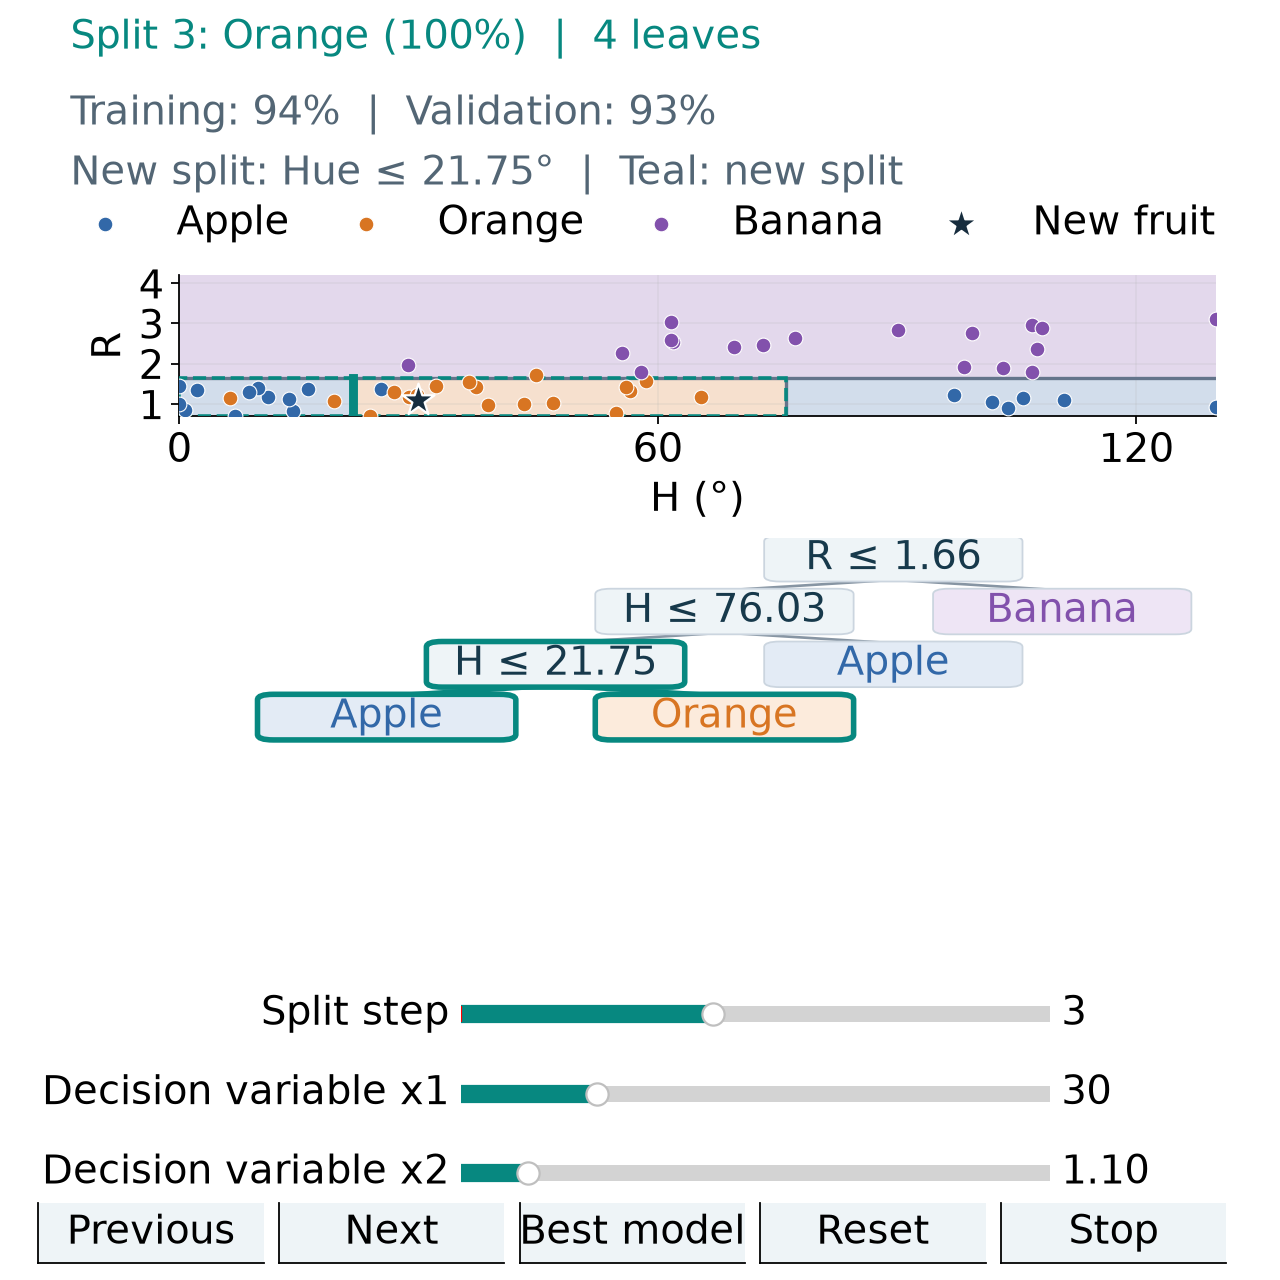

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 18, "axes.labelsize": 18,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=18, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=18, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 2.22 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(18)
            slider.valtext.set_fontsize(18)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .94 / len(commands) - .012)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.03 + i * (width + .012), .25 / height, width, .48 / height]),
                            label,
                            color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(18)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        lower = ((self.tree_ax.get_position().y0 - .02) * height
                 if hasattr(self, "tree_ax") else max(0, self.ax.get_position().y0 * height - .78))
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "180px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()


def make_messages(seed, count=240, spam_fraction=.35):
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

def make_tree_fruit(seed=72):
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15]] * 30 + [[108, 1.15]] * 30
                       + [[32, 1.15]] * 60
                       + [[55, 2.7]] * 30 + [[105, 2.5]] * 30)
    spreads = np.array([[12, .25]] * 60 + [[15, .25]] * 60 + [[12, .5]] * 60)
    values = centers + rng.normal(size=(len(labels), 2)) * spreads
    return np.clip(values, [0, .7], [130, 4.2]), labels


fruit, labels = make_tree_fruit()
class_names = np.array(["Apple", "Orange", "Banana"])
class_colors = [BLUE, ORANGE, PURPLE]
train_id, validation_id = train_test_split(np.arange(len(labels)), test_size=.3,
                                         stratify=labels, random_state=72)
tree_models = {0: DecisionTreeClassifier(min_samples_split=len(train_id) + 1,
                                       random_state=72).fit(fruit[train_id], labels[train_id])}
for step in range(1, 8):
    tree_models[step] = DecisionTreeClassifier(max_leaf_nodes=step + 1, max_depth=7,
                                             random_state=72).fit(fruit[train_id], labels[train_id])
candidate_steps = (1, 2, 3, 5, 7)
validation_scores = {step: model.score(fruit[validation_id], labels[validation_id])
                     for step, model in tree_models.items()}
best_step = max(candidate_steps, key=lambda step: (validation_scores[step], -step))
hue_grid, shape_grid = np.meshgrid(np.linspace(0, 130, 261), np.linspace(.7, 4.2, 101))
fruit_grid = np.c_[hue_grid.ravel(), shape_grid.ravel()]
region_cache = {step: model.predict(fruit_grid).reshape(hue_grid.shape)
                for step, model in tree_models.items()}


def tree_geometry(model):
    tree = model.tree_
    splits, leaves = {}, []

    def visit(node, bounds, path):
        x0, x1, y0, y1 = bounds
        if tree.children_left[node] < 0:
            counts = tree.value[node, 0]
            leaves.append({"node": node, "bounds": bounds,
                           "probability": counts / counts.sum(),
                           "prediction": int(counts.argmax())})
            return
        feature, threshold = int(tree.feature[node]), float(tree.threshold[node])
        if feature == 0:
            line = np.array([[threshold, y0], [threshold, y1]])
            left, right = (x0, threshold, y0, y1), (threshold, x1, y0, y1)
        else:
            line = np.array([[x0, threshold], [x1, threshold]])
            left, right = (x0, x1, y0, threshold), (x0, x1, threshold, y1)
        splits[path] = {"node": node, "bounds": bounds, "line": line,
                        "feature": feature, "threshold": threshold}
        visit(tree.children_left[node], left, path + (0,))
        visit(tree.children_right[node], right, path + (1,))

    visit(0, (0., 130., .7, 4.2), ())
    return splits, leaves


geometry_cache = {step: tree_geometry(model) for step, model in tree_models.items()}
new_splits = {0: None}
for step in range(1, 8):
    previous, current = geometry_cache[step - 1][0], geometry_cache[step][0]
    added = current.keys() - previous.keys()
    assert len(added) == 1 and previous.keys() <= current.keys()
    for path in previous:
        np.testing.assert_allclose(current[path]["line"], previous[path]["line"])
    new_splits[step] = current[added.pop()]


def tree_nodes(model):
    tree = model.tree_
    nodes = {}

    def visit(node, path):
        leaf = tree.children_left[node] < 0
        prediction = int(tree.value[node, 0].argmax())
        nodes[path] = {"node": node, "leaf": leaf, "prediction": prediction}
        if not leaf:
            visit(tree.children_left[node], path + (0,))
            visit(tree.children_right[node], path + (1,))

    visit(0, ())
    return nodes


node_cache = {step: tree_nodes(model) for step, model in tree_models.items()}
final_paths = node_cache[7]
def layout_tree(path=()):
    if final_paths[path]["leaf"]:
        return {path: (0., len(path))}
    left = layout_tree(path + (0,))
    right = layout_tree(path + (1,))
    depths = {depth for _, depth in left.values()} & {depth for _, depth in right.values()}
    separation = max(max(x for x, d in left.values() if d == depth)
                     - min(x for x, d in right.values() if d == depth) + 1.
                     for depth in depths)
    positions = {p: (x - separation / 2, d) for p, (x, d) in left.items()}
    positions.update({p: (x + separation / 2, d) for p, (x, d) in right.items()})
    positions[path] = (0., len(path))
    return positions


raw_positions = layout_tree()
x_min = min(x for x, _ in raw_positions.values()) - .55
x_max = max(x for x, _ in raw_positions.values()) + .55
tree_positions = {path: ((x - x_min) / (x_max - x_min), .95 - .125 * depth)
                  for path, (x, depth) in raw_positions.items()}
tree_box_width = .70 / (x_max - x_min)


def render_tree_structure(view, step):
    from matplotlib.patches import FancyBboxPatch
    if not hasattr(view, "tree_ax"):
        view.ax.set_position([.14, .675, .81, .11])
        view.tree_ax = view.figure.add_axes([.025, .25, .95, .33])
        view.status.set_position((.055, .962))
        view.detail.set_position((.055, .934))
        for index, slider in enumerate(view.controls.values()):
            slider.ax.set_position([.36, .195 - .062 * index, .46, .025])
        for button in view.buttons.values():
            x, _, width, _ = button.ax.get_position().bounds
            button.ax.set_position([x, .013, width, .047])
    ax = view.tree_ax
    ax.clear()
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.set_axis_off()
    nodes = node_cache[step]
    latest = next(iter(geometry_cache[step][0].keys() - geometry_cache[step - 1][0].keys())) if step else None
    new_paths = {latest, latest + (0,), latest + (1,)} if latest is not None else set()
    edges, artists = {}, {}
    for path in nodes:
        if not path:
            continue
        parent = path[:-1]
        x0, y0 = tree_positions[parent]
        x1, y1 = tree_positions[path]
        color = TEAL if parent == latest else "#8795a3"
        edge, = ax.plot([x0, x1], [y0 - .05, y1 + .05], color=color,
                        linewidth=2.2 if parent == latest else 1.2, zorder=1)
        edges[path] = edge
    tree = tree_models[step].tree_
    for path, info in nodes.items():
        x, y = tree_positions[path]
        node = info["node"]
        if info["leaf"]:
            label = class_names[info["prediction"]]
            color = class_colors[info["prediction"]]
            fill = ["#e3ebf5", "#fcebdc", "#eee5f5"][info["prediction"]]
        else:
            feature = ["H", "R"][tree.feature[node]]
            label = f"{feature} ≤ {tree.threshold[node]:.2f}"
            color, fill = "#17394b", "#eef4f7"
        box = FancyBboxPatch((x - tree_box_width / 2, y - .045), tree_box_width, .09,
                             boxstyle="round,pad=0.009,rounding_size=0.013",
                             facecolor=fill, edgecolor=TEAL if path in new_paths else "#cbd5df",
                             linewidth=2.5 if path in new_paths else .8, zorder=3)
        ax.add_patch(box)
        text = ax.text(x, y, label, ha="center", va="center", fontsize=18,
                       color=color, zorder=4)
        artists[path] = {"box": box, "text": text}
    return {"nodes": nodes, "positions": {p: tree_positions[p] for p in nodes},
            "new_paths": new_paths, "edges": edges, "artists": artists}


def render_tree(view, step, hue, shape):
    from matplotlib.patches import Rectangle
    step = int(step)
    structure = render_tree_structure(view, step)
    model = tree_models[step]
    query = np.array([[hue, shape]])
    predicted = int(model.predict(query)[0])
    probability = model.predict_proba(query)[0]
    train_accuracy = model.score(fruit[train_id], labels[train_id])
    splits, leaves = geometry_cache[step]
    latest = new_splits[step]
    ax = view.ax
    for leaf in leaves:
        x0, x1, y0, y1 = leaf["bounds"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0,
                               facecolor=class_colors[leaf["prediction"]],
                               edgecolor="none", alpha=.22, zorder=0))
    for split in splits.values():
        line = split["line"]
        ax.plot(line[:, 0], line[:, 1], color="#64748b", linewidth=1.5, zorder=2)
    if latest is not None:
        x0, x1, y0, y1 = latest["bounds"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                               edgecolor=TEAL, linestyle="--", linewidth=1.6, zorder=4))
        line = latest["line"]
        ax.plot(line[:, 0], line[:, 1], color=TEAL, linewidth=4, zorder=4)
    for value, (color, name) in enumerate(zip(class_colors, class_names)):
        selected = validation_id[labels[validation_id] == value]
        ax.scatter(fruit[selected, 0], fruit[selected, 1], color=color, s=44,
                   edgecolor="white", linewidth=.5, label=name, zorder=5)
    ax.scatter([hue], [shape], s=230, marker="*", color="#172d3e",
               edgecolor="white", linewidth=1, label="New fruit", zorder=6)
    ax.set(xlim=(0, 130), ylim=(.7, 4.2), xlabel="H (°)",
           ylabel="R", xticks=[0, 60, 120], yticks=[1, 2, 3, 4])
    ax.tick_params(labelsize=18)
    ax.set_title("", fontsize=18)
    handles, names = ax.get_legend_handles_labels()
    if not hasattr(view, "fruit_legend"):
        view.fruit_legend = view.figure.legend(handles, names, loc="center",
                                               bbox_to_anchor=(.5, .825), ncol=4,
                                               fontsize=18, columnspacing=.9,
                                               frameon=False)
    if latest is None:
        rule = "No split: one leaf for every fruit"
    else:
        feature = ["Hue", "Length / width"][latest["feature"]]
        unit = "°" if latest["feature"] == 0 else ""
        rule = f"New split: {feature} ≤ {latest['threshold']:.2f}{unit}"
    view.status.set_text(f"Split {step}: {class_names[predicted]} ({probability[predicted]:.0%})"
                         + f"  |  {len(leaves)} {'leaf' if len(leaves) == 1 else 'leaves'}")
    view.detail.set_text(f"Training: {train_accuracy:.0%}  |  Validation: {validation_scores[step]:.0%}\n"
                         + rule + "  |  Teal: new split")
    return {"prediction": predicted, "probability": probability, "model": model,
            "query": query, "train_accuracy": train_accuracy,
            "validation_accuracy": validation_scores[step], "regions": region_cache[step],
            "splits": splits, "leaves": leaves, "new_split": latest, "structure": structure}


tree_demo = ClassificationExplorer("tree", render_tree, [
    ("step", "Split step", 0, 7, 0, 1, "%0.0f"),
    ("hue", "Decision variable x1", 0, 130, 30, 1, "%0.0f"),
    ("shape", "Decision variable x2", .7, 4.2, 1.1, .05, "%0.2f"),
], actions=[
    ("Previous", lambda view: view.set_values(step=max(0, int(view.controls["step"].val) - 1))),
    ("Next", lambda view: view.set_values(step=min(7, int(view.controls["step"].val) + 1))),
    ("Best model", lambda view: view.set_values(step=best_step)),
])
if CLASSIFICATION_STATIC:
    tree_demo.set_values(step=3)
tree_demo.start()


## 측정 조건과 분류 규칙의 한계

- 특징 하나씩 분할하므로 각 말단 노드의 영역은 직사각형이다. 데이터가 조금만 달라져도 임곗값과 트리 구조가 바뀔 수 있다.
- 깊이나 최소 말단 표본 수를 제한하면 복잡도를 줄일 수 있지만, 빠진 특징을 보완하지는 못한다.
- 조명과 품종이 달라지면 규칙의 성능도 달라질 수 있다. 검증 자료로 분할 수를 고른 뒤 별도 시험 데이터(test data)로 평가한다.
